In [ ]:
import sys
sys.path.insert(0, "../../..")  # Adjust path to trovolut package
import numpy as np
from trovolut.qm import gpu4pyscf_wrapper as qm


In [ ]:
import numpy as np
from trovolut.qm import gpu4pyscf_wrapper as qm

# toy atomic masses in a.u. (you'd want real masses if doing MD)
MASS = {"H": 1837.0, "O": 16 * 1837.0}  # proton ~1837 me

eta = 0.01  # step size

# --- init QM geometry ---
atoms = [
    ('O', (0.000, 0.000, 0.000)),
    ('H', (0.758, 0.000, 0.504)),
    ('H', (-0.758, 0.000, 0.504)),
]

mol = qm.create_molecule(atoms, basis="6-31g", unit="Angstrom")


/Users/luismantilla/Desktop/UofT/2025-2/Projects/evolutionary-qmmm/src/trotvol/qm/gpu4pyscf_wrapper.py:26: UserWarning: gpu4pyscf is not installed. Please install it with: pip install gpu4pyscf
  warnings.warn(


converged SCF energy = -75.964870085005
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O    -0.0279823616    -0.0000000000     0.0764632234
1 H    -0.0121436601    -0.0000000000    -0.0630438454
2 H     0.0507675964     0.0000000000    -0.0341162382
----------------------------------------------
step 0: E = -75.964870 Ha, mm=[2. 0. 0.]
converged SCF energy = -75.964870085005
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O    -0.0279823616    -0.0000000000     0.0764632234
1 H    -0.0121436601    -0.0000000000    -0.0630438454
2 H     0.0507675964     0.0000000000    -0.0341162382
----------------------------------------------
step 1: E = -75.964870 Ha, mm=[2. 0. 0.]
converged SCF energy = -75.964870085005
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O    -0.0279823616    -0.0000000000     0.0764632234
1 H    -0.0121436601    -0.0000000

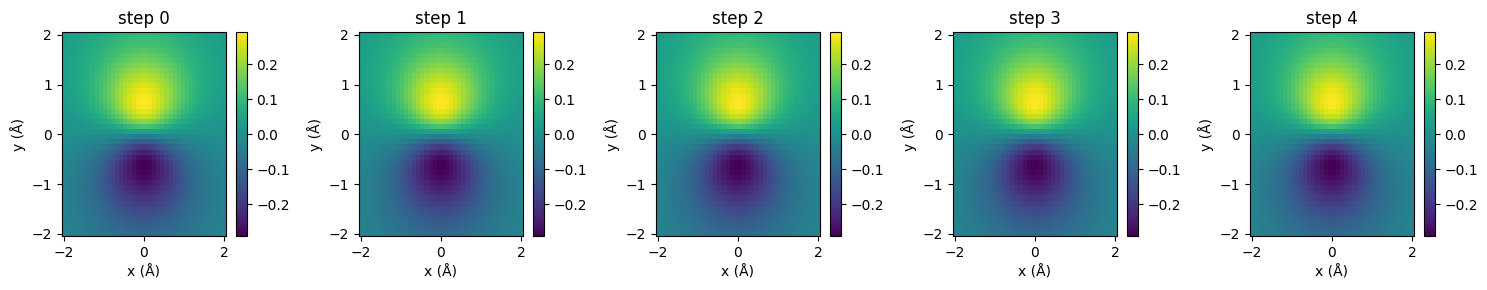

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pyscf.tools import cubegen
from trovolut.qm import gpu4pyscf_wrapper as qm

# ---------- config ----------
basis = "6-31g"
n_steps = 5
eta = 0.01
plot_slice_axis = 2  # 0->yz slice (x const), 1->xz, 2->xy
slice_index = None   # None -> middle of the box
orbital_kind = "HOMO"  # "HOMO" or "LUMO"

MASS = {"H": 1837.0, "O": 16 * 1837.0}
m_mm = 1837.0

# ---------- init geometry ----------
atoms = [
    ('O', (0.000, 0.000, 0.000)),
    ('H', (0.758, 0.000, 0.504)),
    ('H', (-0.758, 0.000, 0.504)),
]
mol = qm.create_molecule(atoms, basis=basis, unit="Angstrom")

# one MM charge sitting nearby
mm_charge = np.array([[2.0, 0.0, 0.0, +1.0]])  # x,y,z,q in Angstrom/e

# we’ll store orbital grids over time
orbital_grids = []

for step in range(n_steps):
    # ---- QM/MM SCF ----
    res = qm.compute_hf_ground_state(mol, external_potential=mm_charge)
    mf = res["mf"]

    # pick HOMO or LUMO index
    nocc = mol.nelectron // 2
    if orbital_kind.upper() == "HOMO":
        mo_idx = nocc - 1
    elif orbital_kind.upper() == "LUMO":
        mo_idx = nocc
    else:
        raise ValueError("orbital_kind must be HOMO or LUMO")

    # ---- build a cube grid for this MO ----
    # cubegen.orbital can directly generate a cube file on disk, but
    # we want the raw grid. We replicate a tiny version below.

    # bounding box for sampling (Angstrom)
    qm_coords = np.array([a[1] for a in mol._atom])
    center = qm_coords.mean(axis=0)
    extent = 2.0  # Å in each direction around center
    ngrid = 40    # resolution per axis

    # grid axes
    xs = np.linspace(center[0]-extent, center[0]+extent, ngrid)
    ys = np.linspace(center[1]-extent, center[1]+extent, ngrid)
    zs = np.linspace(center[2]-extent, center[2]+extent, ngrid)
    X, Y, Z = np.meshgrid(xs, ys, zs, indexing='ij')
    coords = np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=1)

    # evaluate MO ψ(r) on that grid
    # PySCF AO eval:
    ao = mol.eval_gto("GTOval", coords)             # (npts, nbas)
    mo_coeff = mf.mo_coeff[:, mo_idx]               # (nbas,)
    psi = ao @ mo_coeff                             # (npts,)
    psi_grid = psi.reshape(ngrid, ngrid, ngrid)     # 3D field

    orbital_grids.append(psi_grid.copy())

    # ---- forces on QM nuclei ----
    grad_method = mf.nuc_grad_method()
    grad = grad_method.kernel()            # dE/dR_A in Ha/Bohr
    qm_forces = -grad                      # forces

    # ---- crude MM force (Coulomb monopole approx) ----
    total_q = mol.charge  # super crude proxy
    r_mm = mm_charge[0, :3]
    r_qm_centroid = center
    vec = r_qm_centroid - r_mm
    dist = np.linalg.norm(vec)
    F_mm = (total_q * mm_charge[0, 3]) * vec / dist**3

    # ---- update QM nuclei ----
    qm_masses = np.array([MASS[sym] for sym, _ in mol._atom])
    new_qm_coords = qm_coords + eta * (qm_forces / qm_masses[:, None])

    # write new coords back to mol
    for i, (sym, _) in enumerate(mol._atom):
        mol._atom[i] = (sym, new_qm_coords[i].tolist())
    mol.build(False, False)

    # ---- update MM site ----
    mm_charge[0, :3] = r_mm + eta * (F_mm / m_mm)

    print(f"step {step}: E = {res['energy']:.6f} Ha, mm={mm_charge[0,:3]}")

# ---------- visualization ----------
# We now have orbital_grids[step][ix,iy,iz] for each step.

# choose a slice to plot
vol = orbital_grids[0]
nx, ny, nz = vol.shape

if slice_index is None:
    if plot_slice_axis == 0:
        slice_index = nx // 2
    elif plot_slice_axis == 1:
        slice_index = ny // 2
    else:
        slice_index = nz // 2

fig, axes = plt.subplots(1, len(orbital_grids), figsize=(3*len(orbital_grids), 3))

if len(orbital_grids) == 1:
    axes = [axes]

for i, vol in enumerate(orbital_grids):
    if plot_slice_axis == 0:
        sl = vol[slice_index, :, :]
        xlabel, ylabel = "y (Å)", "z (Å)"
        xgrid, ygrid = np.meshgrid(ys, zs, indexing='ij')
    elif plot_slice_axis == 1:
        sl = vol[:, slice_index, :]
        xlabel, ylabel = "x (Å)", "z (Å)"
        xgrid, ygrid = np.meshgrid(xs, zs, indexing='ij')
    else:
        sl = vol[:, :, slice_index]
        xlabel, ylabel = "x (Å)", "y (Å)"
        xgrid, ygrid = np.meshgrid(xs, ys, indexing='ij')

    ax = axes[i]
    im = ax.pcolormesh(xgrid, ygrid, sl.real, shading='auto')
    ax.set_title(f"step {i}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage.measure import marching_cubes
import imageio.v2 as imageio
from trovolut.qm import gpu4pyscf_wrapper as qm

ANG2BOHR = 1.8897259886

################ CONFIG ################

n_steps = 20
extent = 1.5          # Å half-box around initial center (tight box)
ngrid = 36
orbital_kind = "HOMO" # HOMO hugs atoms better than some diffuse LUMO
geom_step_qm = 0.4    # huge, to exaggerate nuclear distortion (Å-like scale)
mm_path_step = np.array([0.3, 0.0, 0.0])  # Å per step, large sweep

################ HELPERS ################

def eval_mo_grid(mol, mf, mo_idx, box_center, extent, ngrid):
    # build cube in Å
    xs = np.linspace(box_center[0]-extent, box_center[0]+extent, ngrid)
    ys = np.linspace(box_center[1]-extent, box_center[1]+extent, ngrid)
    zs = np.linspace(box_center[2]-extent, box_center[2]+extent, ngrid)

    X, Y, Z = np.meshgrid(xs, ys, zs, indexing='ij')
    coords = np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=1)  # Å

    # convert to Bohr for AO eval
    ao = mol.eval_gto("GTOval", coords * ANG2BOHR)  # (npts, nbas)

    mo = mf.mo_coeff[:, mo_idx]  # (nbas,)
    psi = ao @ mo                # (npts,)
    psi_grid = psi.reshape(ngrid, ngrid, ngrid)

    return psi_grid, xs, ys, zs

def add_surface(ax, vol, xs, ys, zs, level, color):
    verts, faces, _, _ = marching_cubes(
        volume=vol,
        level=level,
        spacing=(xs[1]-xs[0], ys[1]-ys[0], zs[1]-zs[0])
    )
    mesh = Poly3DCollection(verts[faces], alpha=0.45)
    mesh.set_edgecolor("none")
    mesh.set_facecolor(color)
    ax.add_collection3d(mesh)

def render_frame(step_idx, qm_coords, psi_grid, xs, ys, zs, out_path):
    fig = plt.figure(figsize=(4,4))
    ax = fig.add_subplot(111, projection='3d')

    # choose iso adaptively: small-ish fraction of max amplitude
    amp = np.max(np.abs(psi_grid))
    iso_try = 0.3 * amp  # 30% of max amplitude in this frame

    plotted_any = False
    try:
        add_surface(ax, psi_grid, xs, ys, zs, +iso_try, "blue")
        plotted_any = True
    except Exception:
        pass
    try:
        add_surface(ax, -psi_grid, xs, ys, zs, +iso_try, "red")
        plotted_any = True
    except Exception:
        pass

    # fallback: plot |psi|
    if not plotted_any:
        try:
            add_surface(ax, np.abs(psi_grid), xs, ys, zs, iso_try, "purple")
        except Exception:
            pass

    # draw QM atoms
    qc = np.array(qm_coords)
    ax.scatter(qc[:,0], qc[:,1], qc[:,2], s=60, c="black", depthshade=True)

    # set box
    ax.set_xlim(xs[0], xs[-1])
    ax.set_ylim(ys[0], ys[-1])
    ax.set_zlim(zs[0], zs[-1])

    ax.set_xlabel("x (Å)")
    ax.set_ylabel("y (Å)")
    ax.set_zlabel("z (Å)")
    ax.set_title(f"step {step_idx}")

    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.close(fig)

################ SYSTEM INIT ################

# water geometry
atoms = [
    ('O', (0.000, 0.000, 0.000)),
    ('H', (0.758, 0.000, 0.504)),
    ('H', (-0.758, 0.000, 0.504)),
]

mol = qm.create_molecule(atoms, basis="6-31g", unit="Angstrom")

# start MM charge extremely close (strong field)
mm_charge = np.array([[1.0, 0.0, 0.5, +5.0]])  # x,y,z,q   big +5e

# fix visualization frame in LAB space at the *initial* QM centroid
initial_qm_coords = np.array([a[1] for a in mol._atom])
box_center = initial_qm_coords.mean(axis=0)

frames = []

################ LOOP ################

for step in range(n_steps):
    # solve QM in the field of the MM charge
    res = qm.compute_hf_ground_state(mol, external_potential=mm_charge)
    mf = res["mf"]

    # pick orbital index
    nocc = mol.nelectron // 2
    if orbital_kind.upper() == "HOMO":
        mo_idx = nocc - 1
    else:
        mo_idx = nocc

    # sample MO (HOMO here) on fixed box in lab frame
    psi_grid, xs, ys, zs = eval_mo_grid(
        mol, mf, mo_idx,
        box_center=box_center,
        extent=extent,
        ngrid=ngrid,
    )

    # render + save this frame
    frame_png = f"frame_{step:03d}.png"
    current_qm_coords = [a[1] for a in mol._atom]
    render_frame(step, current_qm_coords, psi_grid, xs, ys, zs, frame_png)
    frames.append(frame_png)

    # get HF nuclear gradient (dE/dR); convert to forces (-grad)
    grad_method = mf.nuc_grad_method()
    grad = grad_method.kernel()     # shape (n_qm,3), Hartree/Bohr
    forces_qm = -grad               # Hartree/Bohr

    # NOTE: forces are in Bohr units; our geometry is in Å.
    # 1 Bohr = 0.529177 Å.
    BOHR2ANG = 1/ANG2BOHR
    forces_qm_ang = forces_qm * BOHR2ANG  # now "Å-like" direction

    # violently shove nuclei along these forces to exaggerate distortion
    qm_coords_arr = np.array(current_qm_coords)
    new_qm_coords = qm_coords_arr + geom_step_qm * forces_qm_ang

    # write back into mol (still Angstrom)
    for i, (sym, _) in enumerate(mol._atom):
        mol._atom[i] = (sym, new_qm_coords[i].tolist())
    mol.build(False, False)

    # drag MM charge across the molecule to force polarization to move
    mm_charge[0, :3] = mm_charge[0, :3] + mm_path_step

    print(f"step {step}: E = {res['energy']:.6f} Ha, mm = {mm_charge[0,:3]}")

################ MAKE GIF ################

imgs = [imageio.imread(p) for p in frames]
imageio.mimsave("orbitals.gif", imgs, duration=0.15)
print("wrote orbitals.gif")

converged SCF energy = -76.0463086074147
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O     0.6859073031     0.0000000000     0.4937865256
1 H    12.9283506195    -0.0000000000     0.4017123471
2 H     0.2593931367    -0.0000000000    -0.1711025097
----------------------------------------------
step 0: E = -76.046309 Ha, mm = [1.3 0.  0.5]
converged SCF energy = -77.4677436357882
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O     0.8030621265     0.0000000000     0.3138788712
1 H    -1.8106152420     0.0000000000     0.4562489852
2 H     0.2362941466    -0.0000000000    -0.1202627827
----------------------------------------------
step 1: E = -77.467744 Ha, mm = [1.6 0.  0.5]
converged SCF energy = -77.2738467978856
--------------- QMMMRHF gradients ---------------
         x                y                z
0 O     0.6321393347    -0.0000000000    -0.0030793814
1 H    -0.9889354049 